# SVM Sentiment Analysis — Amazon Reviews

Analiza sentymentu recenzji Amazon za pomocą SVM z pełnym pipeline'em:
- **TF-IDF** jako reprezentacja tekstu
- **LinearSVC** jako klasyfikator
- **Podział danych**: Train / Validation / Test
- **Cross-validation** na zbiorze treningowym
- **GridSearchCV** — validation set jako niezależny sprawdzian generalizacji
- **Finalna ewaluacja** na zbiorze testowym

```
Cały dataset
│
├── Test (20%)          ← finalna ewaluacja, dotykamy tylko raz na końcu
│
└── Reszta (80%)
    ├── Validation (15% całości ≈ 19% reszty)  ← niezależny sprawdzian po GridSearch
    └── Train (65% całości ≈ 81% reszty)        ← CV + GridSearchCV
```

**Dlaczego warto mieć osobny zbiór walidacyjny obok CV:**
CV wewnątrz GridSearch wybiera parametry na podstawie foldów z `X_train` — wszystkie
pochodzą z tego samego rozkładu. Validation set jest niezależny i pozwala sprawdzić
czy wybrany model rzeczywiście generalizuje poza dane treningowe, a nie tylko dobrze
dopasował się do specyfiki `X_train`. Przy 73k próbkach możemy sobie pozwolić na
oddanie 15% na ten cel bez żadnej straty jakości modelu.

## 1. Importy

In [1]:
import pandas as pd
import numpy as np
import time
import re
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import seaborn as sns
import matplotlib.pyplot as plt

print("Importy zaladowane pomyslnie.")

Importy zaladowane pomyslnie.


## 2. Wczytanie danych

In [2]:
df = pd.read_csv('data/processed_reviews.csv')

print(f"Liczba probek: {len(df)}")
print(f"Kolumny: {df.columns.tolist()}")
print("\nRozklad klas (label):")
print(df['label'].value_counts().sort_index())

df.head(3)

Liczba probek: 89511
Kolumny: ['id', 'full_text', 'score', 'sentiment', 'label']

Rozklad klas (label):
label
0    29837
1    29837
2    29837
Name: count, dtype: int64


,id,full_text,score,sentiment,label
0,497575,It's not equal amounts of each flavor... Just ...,3,0,1
1,333710,Not A Gingerbread Man These do taste very good...,4,1,2
2,275773,"great taste great taste, good price... Always ...",5,1,2


In [3]:
def clean_text(text):
    # 1. Usuwanie tagów HTML
    text = re.sub(r'<[^>]*>', ' ', text)
    # 2. Usuwanie adresów URL
    text = re.sub(r'http[s]?://\S+|www\.\S+', ' ', text)
    # 3. Usuwanie wielokrotnych spacji (opcjonalnie)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Zastosuj to na kolumnie przed wejściem do pipeline'u
df['full_text'] = df['full_text'].apply(clean_text)

## 3. Podział danych: Train / Validation / Test

Stratyfikacja zapewnia taki sam rozkład klas we wszystkich trzech zbiorach.
Zbiór testowy jest od tej chwili odłożony — nie wracamy do niego aż do sekcji 8.

In [4]:
X = df['full_text']
y = df['label']

# Krok 1: Odłóż zbiór testowy (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Krok 2: Z pozostałych 80% wydziel zbiór walidacyjny (0.1875 * 0.80 = 0.15 całości)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1875,
    random_state=42,
    stratify=y_temp
)

print(f"Train:      {len(X_train):>6} probek ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation: {len(X_val):>6} probek ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test:       {len(X_test):>6} probek ({len(X_test)/len(X)*100:.1f}%)")
print("\nRozklad klas w Train:")
print(y_train.value_counts().sort_index())
print("\nRozklad klas w Validation:")
print(y_val.value_counts().sort_index())
print("\nRozklad klas w Test:")
print(y_test.value_counts().sort_index())

Train:       58181 probek (65.0%)
Validation:  13427 probek (15.0%)
Test:        17903 probek (20.0%)

Rozklad klas w Train:
label
0    19394
1    19393
2    19394
Name: count, dtype: int64

Rozklad klas w Validation:
label
0    4476
1    4476
2    4475
Name: count, dtype: int64

Rozklad klas w Test:
label
0    5967
1    5968
2    5968
Name: count, dtype: int64


## 4. Baseline Pipeline

Bazowy pipeline z parametrami wynikającymi z wcześniejszych eksperymentów.

Kluczowe decyzje projektowe:
- `stop_words=None` — negacje ('not', 'no') niosą istotną informację o sentymencie
- `ngram_range=(1,3)` — trigramy łapią frazy jak 'not good at all'
- `min_df=3` — odcina rzadkie cechy, redukuje szum
- `class_weight=None` — klasy są już zbalansowane w danych, wyrównywanie wag byłoby zbędne
- Pipeline gwarantuje brak data leakage — TF-IDF fitowany osobno w każdym foldzie CV

In [5]:
baseline_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=25000,
        stop_words=None,
        ngram_range=(1, 3),
        lowercase=True,
        min_df=3
    )),
    ('svm', LinearSVC(
        C=1,
        max_iter=3000,
        dual='auto',
        random_state=42
    ))
])

print("Pipeline zdefiniowany:")
print(baseline_pipe)

Pipeline zdefiniowany:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=25000, min_df=3,
                                 ngram_range=(1, 3))),
                ('svm', LinearSVC(C=1, max_iter=3000, random_state=42))])


## 5. Baseline Cross-Validation

5-fold CV na `X_train` — punkt odniesienia przed GridSearch.
Sprawdzamy czy parametry z wcześniejszych eksperymentów są dobrym punktem startowym
i czy model jest stabilny (mała wariancja między foldami).

Uruchamianie 5-fold CV (baseline)...
Czas: 35.7s

Baseline CV F1-macro: 0.7435 +/- 0.0030
Wyniki per fold:      [0.7418 0.7384 0.7462 0.7463 0.7446]


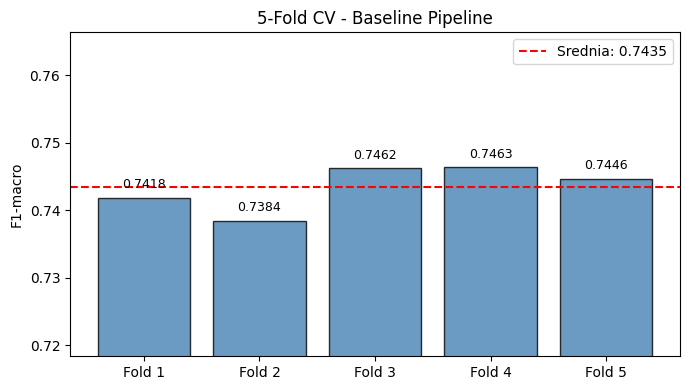

In [6]:
print("Uruchamianie 5-fold CV (baseline)...")
start = time.time()

cv_scores = cross_val_score(
    baseline_pipe,
    X_train, y_train,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

print(f"Czas: {time.time() - start:.1f}s")
print(f"\nBaseline CV F1-macro: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
print(f"Wyniki per fold:      {np.round(cv_scores, 4)}")

fig, ax = plt.subplots(figsize=(7, 4))
folds = [f'Fold {i+1}' for i in range(len(cv_scores))]
bars = ax.bar(folds, cv_scores, color='steelblue', alpha=0.8, edgecolor='black')
ax.axhline(cv_scores.mean(), color='red', linestyle='--',
           label=f'Srednia: {cv_scores.mean():.4f}')
ax.set_ylim(max(0, cv_scores.min() - 0.02), min(1, cv_scores.max() + 0.02))
ax.set_ylabel('F1-macro')
ax.set_title('5-Fold CV - Baseline Pipeline')
ax.legend()
for bar, score in zip(bars, cv_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{score:.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 6. GridSearchCV — dobór hiperparametrów

GridSearchCV przeszukuje siatkę parametrów używając **3-fold CV na `X_train`**.
Używamy 3 foldów zamiast 5 żeby skrócić czas — mamy dużo danych i dodatkowy
niezależny sprawdzian w postaci validation setu.

Po zakończeniu `refit=True` automatycznie trenuje finalny model na całym `X_train`
z najlepszymi znalezionymi parametrami.

Siatka testuje:
- `max_features` / `ngram_range` — bogactwo reprezentacji tekstu
- `C` — siła regularyzacji (mniejsze C = silniejsza regularyzacja = mniejsze ryzyko przeuczenia)

`class_weight` wyłączony z siatki — klasy są już zbalansowane w danych,
więc przeszukiwanie tego parametru byłoby stratą czasu.

In [7]:
gs_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        stop_words=None,
        min_df=3
    )),
    ('svm', LinearSVC(
        max_iter=3000,
        dual='auto',
        random_state=42
    ))
])

# 3 x 2 x 3 = 18 kombinacji x 3 foldy = 54 fity
param_grid = {
    'tfidf__max_features': [25000, 30000, None],
    'tfidf__ngram_range':  [(1, 2), (1, 3)],
    'svm__C':              [0.3, 1, 5],
}

grid_search = GridSearchCV(
    gs_pipe,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Liczba kombinacji: 18 x 3 foldy = 54 fity")
print("Uruchamianie GridSearchCV...")
start = time.time()

grid_search.fit(X_train, y_train)

print(f"\nGotowe! Czas: {time.time() - start:.1f}s")
print(f"\nNajlepsze parametry:")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"\nNajlepszy CV F1-macro (train): {grid_search.best_score_:.4f}")

Liczba kombinacji: 18 x 3 foldy = 54 fity
Uruchamianie GridSearchCV...
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Gotowe! Czas: 399.6s

Najlepsze parametry:
  svm__C: 0.3
  tfidf__max_features: None
  tfidf__ngram_range: (1, 3)

Najlepszy CV F1-macro (train): 0.7647


In [8]:
# Top 10 kombinacji
# Mala roznica miedzy top1 a top10 = model stabilny, nie ma jednej magicznej kombinacji
cv_results = pd.DataFrame(grid_search.cv_results_)
top10 = (cv_results
         .sort_values('mean_test_score', ascending=False)
         .head(10)[['param_tfidf__max_features', 'param_tfidf__ngram_range',
                    'param_svm__C',
                    'mean_test_score', 'std_test_score']]
         .reset_index(drop=True))

top10.columns = ['max_features', 'ngram_range', 'C', 'mean_F1', 'std_F1']
top10['mean_F1'] = top10['mean_F1'].round(4)
top10['std_F1']  = top10['std_F1'].round(4)

print("Top 10 kombinacji hiperparametrow:")
display(top10)

Top 10 kombinacji hiperparametrow:


,max_features,ngram_range,C,mean_F1,std_F1
0,None,"(1, 3)",0.3,0.7647,0.0029
1,None,"(1, 2)",0.3,0.7625,0.0036
2,30000,"(1, 3)",0.3,0.7595,0.0028
3,25000,"(1, 3)",0.3,0.7588,0.0022
4,30000,"(1, 2)",0.3,0.7586,0.0033
5,25000,"(1, 2)",0.3,0.7582,0.0030
6,None,"(1, 3)",1.0,0.7571,0.0033
7,None,"(1, 2)",1.0,0.7519,0.0027
8,None,"(1, 3)",5.0,0.7472,0.0034
9,30000,"(1, 3)",1.0,0.7445,0.0035


## 7. Ewaluacja na zbiorze walidacyjnym

Validation set był niewidoczny podczas GridSearch — pochodzi spoza `X_train`,
więc daje niezależną ocenę czy najlepszy model rzeczywiście generalizuje.

Jeśli wynik na validation jest wyraźnie niższy niż CV F1 z GridSearch (>3-4 pp),
to sygnał że model przeuczył się do specyfiki `X_train`.

In [9]:
best_model = grid_search.best_estimator_

y_val_pred = best_model.predict(X_val)
val_f1 = f1_score(y_val, y_val_pred, average='macro')

print("=" * 55)
print("WYNIKI NA ZBIORZE WALIDACYJNYM")
print("=" * 55)
print(f"CV F1-macro (GridSearch, train): {grid_search.best_score_:.4f}")
print(f"F1-macro    (validation):        {val_f1:.4f}")
diff = grid_search.best_score_ - val_f1
print(f"Roznica (CV - val):              {diff:+.4f}",
      "<-- ok" if diff < 0.04 else "<-- uwaga, mozliwe przeuczenie")
print()
print(classification_report(
    y_val, y_val_pred,
    target_names=['Negative (1-2)', 'Neutral (3)', 'Positive (4-5)']
))

WYNIKI NA ZBIORZE WALIDACYJNYM
CV F1-macro (GridSearch, train): 0.7647
F1-macro    (validation):        0.7725
Roznica (CV - val):              -0.0078 <-- ok

                precision    recall  f1-score   support

Negative (1-2)       0.76      0.78      0.77      4476
   Neutral (3)       0.71      0.68      0.69      4476
Positive (4-5)       0.84      0.87      0.85      4475

      accuracy                           0.77     13427
     macro avg       0.77      0.77      0.77     13427
  weighted avg       0.77      0.77      0.77     13427



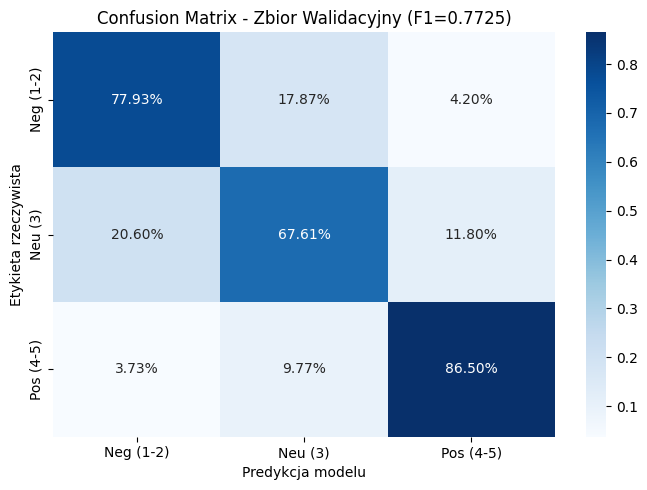

In [10]:
cm_val = confusion_matrix(y_val, y_val_pred)
cm_val_pct = cm_val.astype(float) / cm_val.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_val_pct, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'],
            yticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix - Zbior Walidacyjny (F1={val_f1:.4f})')
plt.tight_layout()
plt.show()

## 8. Finalna ewaluacja na zbiorze testowym

> **Uwaga**: Ta sekcja uruchamiana jest tylko raz, po zakończeniu wszystkich eksperymentów.
> Wyniki testowe nie mogą wpływać na żadne dalsze decyzje modelarskie.

Przed finalnym testem refitujemy model na połączonych danych train + validation,
żeby w pełni wykorzystać wszystkie dostępne oznaczone dane.

In [11]:
import copy

X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

final_model = copy.deepcopy(best_model)
final_model.fit(X_trainval, y_trainval)

y_test_pred = final_model.predict(X_test)
test_f1 = f1_score(y_test, y_test_pred, average='macro')

print("=" * 55)
print("FINALNE WYNIKI NA ZBIORZE TESTOWYM")
print("=" * 55)
print(f"CV F1-macro  (GridSearch, train): {grid_search.best_score_:.4f}")
print(f"F1-macro     (validation):        {val_f1:.4f}")
print(f"F1-macro     (test):              {test_f1:.4f}")
print()
print(classification_report(
    y_test, y_test_pred,
    target_names=['Negative (1-2)', 'Neutral (3)', 'Positive (4-5)']
))

FINALNE WYNIKI NA ZBIORZE TESTOWYM
CV F1-macro  (GridSearch, train): 0.7647
F1-macro     (validation):        0.7725
F1-macro     (test):              0.7761

                precision    recall  f1-score   support

Negative (1-2)       0.78      0.77      0.78      5967
   Neutral (3)       0.70      0.69      0.70      5968
Positive (4-5)       0.85      0.87      0.86      5968

      accuracy                           0.78     17903
     macro avg       0.78      0.78      0.78     17903
  weighted avg       0.78      0.78      0.78     17903



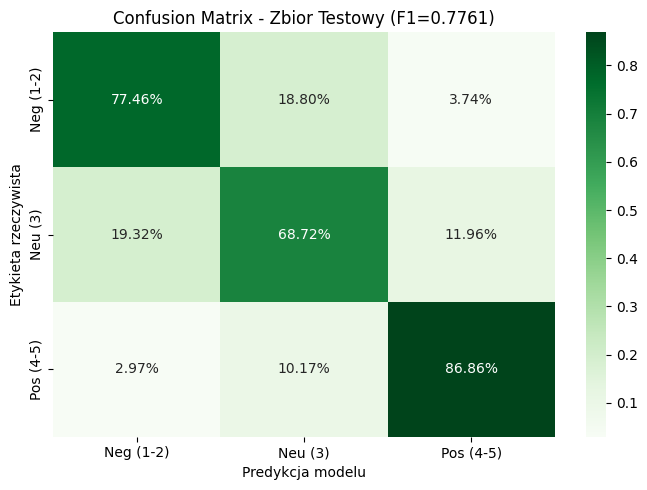

In [12]:
cm_test = confusion_matrix(y_test, y_test_pred)
cm_test_pct = cm_test.astype(float) / cm_test.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_test_pct, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'],
            yticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix - Zbior Testowy (F1={test_f1:.4f})')
plt.tight_layout()
plt.show()

## 9. Podsumowanie

In [13]:
print("=" * 55)
print("PODSUMOWANIE EKSPERYMENTU")
print("=" * 55)
print(f"\nPodzial danych:")
print(f"  Train:      {len(X_train):>6} probek ({len(X_train)/len(X)*100:.1f}%)")
print(f"  Validation: {len(X_val):>6} probek ({len(X_val)/len(X)*100:.1f}%)")
print(f"  Test:       {len(X_test):>6} probek ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nWyniki:")
print(f"  Baseline CV F1-macro (5-fold): {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
print(f"  GridSearch CV F1-macro:        {grid_search.best_score_:.4f}")
print(f"  Validation F1-macro:           {val_f1:.4f}")
print(f"  Test F1-macro (FINALNA):       {test_f1:.4f}")
print(f"\nNajlepsze hiperparametry:")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")

PODSUMOWANIE EKSPERYMENTU

Podzial danych:
  Train:       58181 probek (65.0%)
  Validation:  13427 probek (15.0%)
  Test:        17903 probek (20.0%)

Wyniki:
  Baseline CV F1-macro (5-fold): 0.7435 +/- 0.0030
  GridSearch CV F1-macro:        0.7647
  Validation F1-macro:           0.7725
  Test F1-macro (FINALNA):       0.7761

Najlepsze hiperparametry:
  svm__C: 0.3
  tfidf__max_features: None
  tfidf__ngram_range: (1, 3)


## 10. Analiza błędów

In [14]:
results_df = pd.DataFrame({
    'text':      X_test.values,
    'actual':    y_test.values,
    'predicted': y_test_pred
})

errors = results_df[results_df['actual'] != results_df['predicted']]
print(f"Blednych predykcji: {len(errors)} / {len(results_df)} "
      f"({len(errors)/len(results_df)*100:.1f}%)")

label_values = sorted(y.unique())
neg_label = label_values[0]
pos_label = label_values[-1]

extreme = errors[(errors['actual'] == neg_label) & (errors['predicted'] == pos_label)]
print(f"\nSkrajne pomylki (Negatyw -> Pozytyw): {len(extreme)}")

for _, row in extreme.head(5).iterrows():
    print(f"\n[actual={row['actual']} | pred={row['predicted']}]")
    print(f"  {str(row['text'])[:250]}...")

Blednych predykcji: 3996 / 17903 (22.3%)

Skrajne pomylki (Negatyw -> Pozytyw): 223

[actual=0 | pred=2]
  Serious health food If you're out for sheer health benefits without taste and without desirable texture, this one's for you. I did not expect much out of it except health benefits, so I wasn't surprised. You should only try this product if you have e...

[actual=0 | pred=2]
  My cat hates this stuff... I had to but my cat friskee pate canned cat food instead of this canned stuff. My cat lost weight cause she wouldnt eat it. I had 2 different cases from amazon and also different flavors of filet that i had brought from the...

[actual=0 | pred=2]
  I was hoping to love this coffee, but it is very bitter. I have been searching for a smooth, flavorful decaf K cup that I could actually enjoy. I was thrilled to find Folgers Gourmet Lively Columbian medium roast decaf K cup to try, but both my husba...

[actual=0 | pred=2]
  frenchs horseradish mustard first of all I like Frenchs regula